```markdown
# Système de Détection d'Intrusions Réseau (NIDS) Multiclasse avec NSL-KDD

Ce notebook présente une méthodologie rigoureuse, exempte de fuite de données (data leakage), pour entraîner et comparer trois types de classifieurs sur le dataset de référence **NSL-KDD** :
1. **Random Forest** (Forêt Aléatoire)
2. **Multi-Layer Perceptron** (MLP - Réseau de neurones denses)
3. **1D Convolutional Neural Network** (1D-CNN - Réseau de neurones convolutifs)

Tous les artefacts d'inférence seront sauvegardés et packagés de manière autonome pour être facilement intégrés dans une application d'inférence locale ou web.
```

> **Note de provenance** : ce notebook contient le pipeline final utilisé pour les résultats de la Semaine 3 (découpage 70/15/15, Random Forest / MLP / 1D-CNN). Les cellules exploratoires d'essais antérieurs ont été retirées et archivées dans `notebooks/archive/`. Les artefacts exportés se trouvent dans `models/`.


```markdown
## Étape 1 : Configuration & Acquisition du dataset

Nous allons installer les packages requis (notamment `shap`), importer les librairies, fixer les graines de reproductibilité et charger les fichiers locaux d'entraînement et de test.
```

In [1]:
# Installation des packages nécessaires
!pip install -q shap imbalanced-learn

import os
import time
import json
import random
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Dropout, Input, Conv1D, MaxPooling1D, GlobalMaxPooling1D, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
from sklearn.utils.class_weight import compute_class_weight

from imblearn.over_sampling import SMOTE
import shap

# Configuration de la reproductibilité globale
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

print("Version de TensorFlow:", tf.__version__)
print("Configuration initiale terminée.")

Version de TensorFlow: 2.21.0
Configuration initiale terminée.


In [3]:
# Définition des 43 colonnes officielles de NSL-KDD
columns = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
    'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in',
    'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
    'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login',
    'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate',
    'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate',
    'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
    'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate',
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'attack_type', 'difficulty_level'
]

# Chemins locaux sur Google Colab
train_path = "/content/KDDTrain+_20Percent.txt"
test_path = "/content/KDDTest+.txt"

# Téléchargement automatique de secours si nécessaire
if not os.path.exists(train_path) or os.path.getsize(train_path) == 0:
    print("Téléchargement de secours pour KDDTrain+_20Percent.txt...")
    urllib.request.urlretrieve("https://raw.githubusercontent.com/defcom17/NSL-KDD/master/KDDTrain%2B_20Percent.txt", train_path)

if not os.path.exists(test_path) or os.path.getsize(test_path) == 0:
    print("Téléchargement de secours pour KDDTest+.txt...")
    urllib.request.urlretrieve("https://raw.githubusercontent.com/defcom17/NSL-KDD/master/KDDTest%2B.txt", test_path)

# Lecture robuste des datasets
train_df = pd.read_csv(train_path, header=None, names=columns, on_bad_lines='skip')
test_df = pd.read_csv(test_path, header=None, names=columns, on_bad_lines='skip')

# Mappage exhaustif des 39 types d'attaques réseau vers les 5 classes globales officielles
attack_mapping = {
    'normal': 'Normal',
    'back': 'DoS', 'land': 'DoS', 'neptune': 'DoS', 'pod': 'DoS', 'smurf': 'DoS',
    'teardrop': 'DoS', 'mailbomb': 'DoS', 'apache2': 'DoS', 'processtable': 'DoS',
    'udpstorm': 'DoS', 'worm': 'DoS',
    'satan': 'Probe', 'ipsweep': 'Probe', 'portsweep': 'Probe', 'nmap': 'Probe',
    'mscan': 'Probe', 'saint': 'Probe',
    'guess_passwd': 'R2L', 'ftp_write': 'R2L', 'imap': 'R2L', 'phf': 'R2L',
    'multihop': 'R2L', 'warezmaster': 'R2L', 'warezclient': 'R2L', 'spy': 'R2L',
    'sendmail': 'R2L', 'xlock': 'R2L', 'snmpgetattack': 'R2L', 'xsnoop': 'R2L',
    'snmpguess': 'R2L', 'httptunnel': 'R2L', 'named': 'R2L',
    'buffer_overflow': 'U2R', 'loadmodule': 'U2R', 'perl': 'U2R', 'rootkit': 'U2R',
    'ps': 'U2R', 'sqlattack': 'U2R', 'xterm': 'U2R'
}

# Nettoyage et mappage des catégories d'attaques
train_df['attack_category'] = train_df['attack_type'].str.strip().str.lower().map(attack_mapping).fillna('Normal')
test_df['attack_category'] = test_df['attack_type'].str.strip().str.lower().map(attack_mapping).fillna('Normal')

print(f"[Étape 1] Jeu d'entraînement chargé avec succès : {train_df.shape}")
print(f"[Étape 1] Jeu de test chargé avec succès : {test_df.shape}")

[Étape 1] Jeu d'entraînement chargé avec succès : (25192, 44)
[Étape 1] Jeu de test chargé avec succès : (22544, 44)


```markdown
## Étape 2 : Audit & Analyse Exploratoire des Données (EDA)

Nous allons inspecter les dimensions, vérifier l'absence de valeurs manquantes, comptabiliser les doublons exacts et analyser l'important déséquilibre des classes cibles (en particulier pour les attaques rares comme `U2R` et `R2L`).
```

Valeurs manquantes -> Train : 0, Test : 0
Doublons exacts détectés dans le jeu d'entraînement : 0

--- Distribution des classes (Train) ---
Classe Normal    :  13449 (53.39%)
Classe DoS       :   9234 (36.65%)
Classe Probe     :   2289 (9.09%)
Classe R2L       :    209 (0.83%)
Classe U2R       :     11 (0.04%)

--- Distribution des classes (Test) ---
Classe Normal    :   9711 (43.08%)
Classe DoS       :   7460 (33.09%)
Classe R2L       :   2885 (12.80%)
Classe Probe     :   2421 (10.74%)
Classe U2R       :     67 (0.30%)

Ratio de déséquilibre extrême (Normal vs U2R) : 1 à 1222.6


/tmp/ipykernel_874/3152679773.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_df, x='attack_category', order=dist_train.index, palette='viridis')


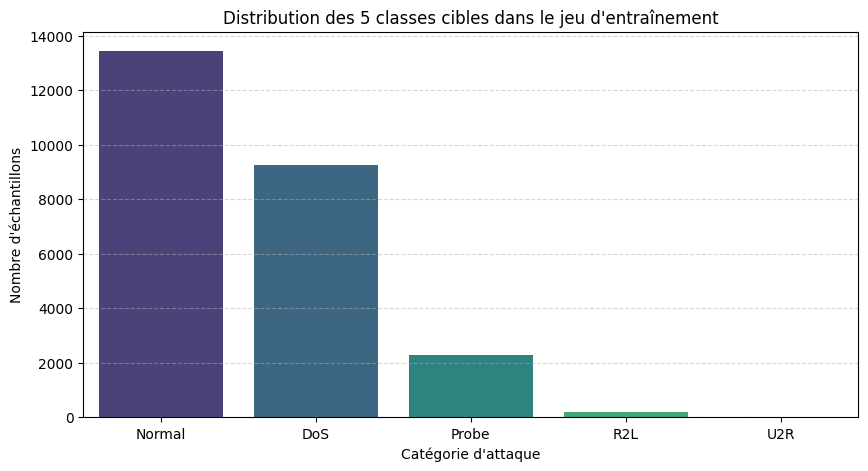

In [4]:
# Audit rapide des types et détection des valeurs manquantes
missing_train = train_df.isnull().sum().sum()
missing_test = test_df.isnull().sum().sum()
print(f"Valeurs manquantes -> Train : {missing_train}, Test : {missing_test}")

# Analyse des doublons exacts
duplicates_train = train_df.duplicated().sum()
print(f"Doublons exacts détectés dans le jeu d'entraînement : {duplicates_train}")

# Distribution des 5 classes cibles sur le jeu d'entraînement
dist_train = train_df['attack_category'].value_counts()
dist_test = test_df['attack_category'].value_counts()

print("\n--- Distribution des classes (Train) ---")
for k, v in dist_train.items():
    ratio = (v / len(train_df)) * 100
    print(f"Classe {k:<10}: {v:>6} ({ratio:.2f}%)")

print("\n--- Distribution des classes (Test) ---")
for k, v in dist_test.items():
    ratio = (v / len(test_df)) * 100
    print(f"Classe {k:<10}: {v:>6} ({ratio:.2f}%)")

# Calcul du ratio de déséquilibre
min_class = dist_train.idxmin()
max_class = dist_train.idxmax()
ratio_unbalance = dist_train[max_class] / dist_train[min_class]
print(f"\nRatio de déséquilibre extrême ({max_class} vs {min_class}) : 1 à {ratio_unbalance:.1f}")

# Visualisation de la distribution
plt.figure(figsize=(10, 5))
sns.countplot(data=train_df, x='attack_category', order=dist_train.index, palette='viridis')
plt.title("Distribution des 5 classes cibles dans le jeu d'entraînement")
plt.xlabel("Catégorie d'attaque")
plt.ylabel("Nombre d'échantillons")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

```markdown
## Étape 3 : Nettoyage, Split Stratifié & Prétraitement sans fuite (Zero Data Leakage)

Pour respecter l'obligation de **zéro fuite de données (Data Leakage)**, nous :
1. Éliminons les doublons exacts.
2. Concaténons brièvement les données brutes pour reconstruire une population unifiée propre, puis réalisons un découpage stratifié rigoureux : **70% Entraînement / 15% Validation / 15% Test**.
3. Créons un `ColumnTransformer` qui sera **uniquement** ajusté (`fit`) sur le jeu d'entraînement puis appliqué (`transform`) sur les ensembles de validation et de test.
```

In [5]:
# Suppression des doublons exacts
train_clean = train_df.drop_duplicates()
test_clean = test_df.drop_duplicates()

# Union globale propre avant redécoupage stratifié unifié
full_df = pd.concat([train_clean, test_clean], axis=0, ignore_index=True)

# Suppression de la colonne d'aide optionnelle et difficulty_level si présente
if 'difficulty_level' in full_df.columns:
    full_df.drop(columns=['difficulty_level'], inplace=True)
if 'attack_type' in full_df.columns:
    full_df.drop(columns=['attack_type'], inplace=True)

# Séparation des features (X) et de la cible (y)
y = full_df['attack_category']
X = full_df.drop(columns=['attack_category'])

# Découpage stratifié unifié : 70% Train, 15% Val, 15% Test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print(f"Dimensions après split stratifié :")
print(f" - Train : {X_train.shape} (cible : {y_train.shape})")
print(f" - Val   : {X_val.shape} (cible : {y_val.shape})")
print(f" - Test  : {X_test.shape} (cible : {y_test.shape})")

# Identification des colonnes numériques et catégorielles
categorical_cols = ['protocol_type', 'service', 'flag']
numerical_cols = [col for col in X_train.columns if col not in categorical_cols]

# Définition et application du ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# AJUSTEMENT UNIQUE SUR LE TRAIN SET
X_train_proc = preprocessor.fit_transform(X_train)
# TRANSFORMATION SANS AJUSTEMENT SUR VAL ET TEST
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

# Encodage de la cible (y)
label_encoder = LabelEncoder()
y_train_enc = label_encoder.fit_transform(y_train)
y_val_enc = label_encoder.transform(y_val)
y_test_enc = label_encoder.transform(y_test)

# Récupération de la liste ordonnée finale des colonnes
cat_features = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols).tolist()
all_features = numerical_cols + cat_features

print(f"\nNombre de features après encodage One-Hot : {X_train_proc.shape[1]}")
print("Classes encodées :", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

Dimensions après split stratifié :
 - Train : (33415, 41) (cible : (33415,))
 - Val   : (7160, 41) (cible : (7160,))
 - Test  : (7161, 41) (cible : (7161,))

Nombre de features après encodage One-Hot : 118
Classes encodées : {'DoS': np.int64(0), 'Normal': np.int64(1), 'Probe': np.int64(2), 'R2L': np.int64(3), 'U2R': np.int64(4)}


```markdown
## Étape 4 : Gestion du déséquilibre de classes

Nous allons calculer les poids de classe de manière équilibrée sur le jeu d'entraînement (`class_weights`), et générer une variante d'entraînement synthétique à l'aide de **SMOTE** (uniquement sur le jeu d'entraînement `X_train_proc` pour éviter tout data leakage).
```

In [6]:
# 1. Calcul des class_weights de manière équilibrée
classes_unique = np.unique(y_train_enc)
weights = compute_class_weight('balanced', classes=classes_unique, y=y_train_enc)
class_weight_dict = dict(zip(classes_unique, weights))

print("Poids de classes calculés :")
for k, v in class_weight_dict.items():
    print(f"  Classe {label_encoder.inverse_transform([k])[0]} ({k}) : {v:.4f}")

# 2. Variante SMOTE (uniquement sur Train)
smote = SMOTE(random_state=SEED)
X_train_smote, y_train_smote = smote.fit_resample(X_train_proc, y_train_enc)

print(f"\nDimensions avant SMOTE : {X_train_proc.shape}")
print(f"Dimensions après SMOTE  : {X_train_smote.shape}")
print("Distribution après SMOTE :", pd.Series(y_train_smote).value_counts().to_dict())

Poids de classes calculés :
  Classe DoS (0) : 0.5719
  Classe Normal (1) : 0.4122
  Classe Probe (2) : 2.0270
  Classe R2L (3) : 3.0854
  Classe U2R (4) : 123.7593

Dimensions avant SMOTE : (33415, 118)
Dimensions après SMOTE  : (81060, 118)
Distribution après SMOTE : {1: 16212, 2: 16212, 3: 16212, 0: 16212, 4: 16212}


```markdown
## Étape 5 : Entraînement et Optimisation des 3 Modèles

### 1. Modèle 1 — Random Forest (Baseline)
Nous configurons une recherche par grille simplifiée pour optimiser `max_depth` (Aucune limite vs 20) sur le jeu de validation en nous basant sur le score **Macro F1**.
```

In [7]:
# Test et sélection des hyperparamètres de Random Forest sur l'ensemble de Validation
best_macro_f1 = -1
best_rf_model = None
best_depth = None

for depth in [None, 20]:
    rf = RandomForestClassifier(
        n_estimators=200,
        max_depth=depth,
        class_weight='balanced',
        random_state=SEED,
        n_jobs=-1
    )
    rf.fit(X_train_proc, y_train_enc)
    val_preds = rf.predict(X_val_proc)
    m_f1 = f1_score(y_val_enc, val_preds, average='macro')
    print(f"Configuration [max_depth={depth}] -> Macro F1 de Validation : {m_f1:.4f}")

    if m_f1 > best_macro_f1:
        best_macro_f1 = m_f1
        best_rf_model = rf
        best_depth = depth

print(f"-> Meilleur modèle Random Forest sélectionné : [max_depth={best_depth}] avec Macro F1 : {best_macro_f1:.4f}")

Configuration [max_depth=None] -> Macro F1 de Validation : 0.9192
Configuration [max_depth=20] -> Macro F1 de Validation : 0.9340
-> Meilleur modèle Random Forest sélectionné : [max_depth=20] avec Macro F1 : 0.9340


```markdown
### 2. Modèle 2 — Multi-Layer Perceptron (MLP)
Nous concevons un réseau dense à 2 couches avec régularisation Dropout et entraînement contrôlé par Early Stopping.
```

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        15,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,813 (93.02 KB)

 Trainable params: 23,813 (93.02 KB)

 Non-trainable params: 0 (0.00 B)

Entraînement du MLP avec ajustement des poids de classes...
Epoch 1/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.8149 - loss: 0.8368 - val_accuracy: 0.8821 - val_loss: 0.3974
Epoch 2/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8905 - loss: 0.3215 - val_accuracy: 0.9028 - val_loss: 0.3299
Epoch 3/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9052 - loss: 0.2640 - val_accuracy: 0.9106 - val_loss: 0.3270
Epoch 4/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9147 - loss: 0.2372 - val_accuracy: 0.9235 - val_loss: 0.2985
Epoch 5/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9204 - loss: 0.2182 - val_accuracy: 0.9271 - val_loss: 0.2894
Epoch 6/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9260 - loss: 0.2174 - val_accuracy: 0.9286 - val_loss: 0.3143
Epoch 7/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9305 - loss: 0.1937 - val_accuracy: 0.9415 - val_loss: 0.2754
Epoch 8/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 1s 

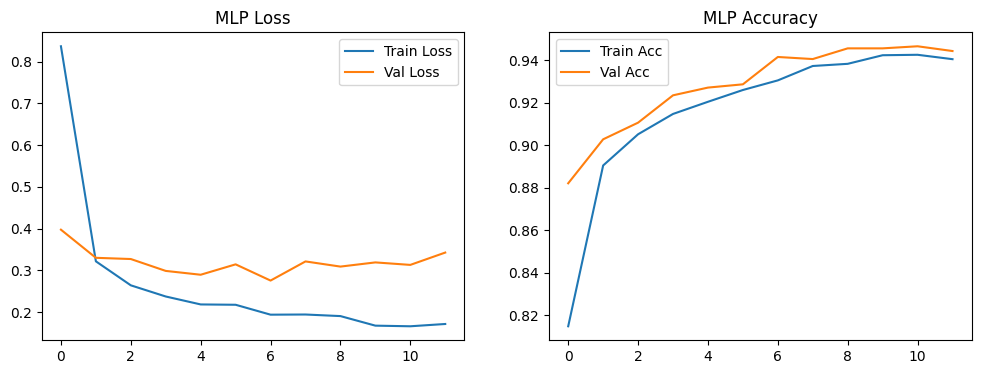

In [8]:
# Répertoire d'exportation des artefacts
os.makedirs('./nids_artifacts', exist_ok=True)

def build_mlp(input_dim):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(128, activation='relu'),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dropout(0.2),
        Dense(5, activation='softmax')
    ])
    model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

mlp_model = build_mlp(X_train_proc.shape[1])
mlp_model.summary()

callbacks_mlp = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ModelCheckpoint('./nids_artifacts/mlp_checkpoint.keras', save_best_only=True, monitor='val_loss')
]

print("Entraînement du MLP avec ajustement des poids de classes...")
history_mlp = mlp_model.fit(
    X_train_proc, y_train_enc,
    validation_data=(X_val_proc, y_val_enc),
    epochs=30,
    batch_size=128,
    class_weight=class_weight_dict,
    callbacks=callbacks_mlp,
    verbose=1
)

# Tracer les courbes d'apprentissage pour le MLP
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_mlp.history['loss'], label='Train Loss')
plt.plot(history_mlp.history['val_loss'], label='Val Loss')
plt.title('MLP Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_mlp.history['accuracy'], label='Train Acc')
plt.plot(history_mlp.history['val_accuracy'], label='Val Acc')
plt.title('MLP Accuracy')
plt.legend()
plt.show()

```markdown
### 3. Modèle 3 — 1D Convolutional Neural Network (1D-CNN)
Les données tabulaires n'ayant pas de corrélation spatiale naturelle comme les images, nous les remodelons sous la forme d'un tenseur 3D `(samples, features, 1)` pour que les filtres convolutifs puissent analyser des motifs séquentiels locaux à travers les features d'un flux réseau.
```

Nouvelles dimensions pour 1D-CNN : (33415, 118, 1)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 118, 64)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 59, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 59, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,541 (131.02 KB)

 Trainable params: 33,541 (131.02 KB)

 Non-trainable params: 0 (0.00 B)

Entraînement du 1D-CNN...
Epoch 1/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 13s 25ms/step - accuracy: 0.5620 - loss: 1.4476 - val_accuracy: 0.8320 - val_loss: 0.8261
Epoch 2/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7441 - loss: 0.9131 - val_accuracy: 0.8155 - val_loss: 0.6405
Epoch 3/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7648 - loss: 0.7509 - val_accuracy: 0.8106 - val_loss: 0.6834
Epoch 4/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7765 - loss: 0.6685 - val_accuracy: 0.8103 - val_loss: 0.6382
Epoch 5/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7924 - loss: 0.6125 - val_accuracy: 0.7809 - val_loss: 0.6415
Epoch 6/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8020 - loss: 0.5604 - val_accuracy: 0.7946 - val_loss: 0.5933
Epoch 7/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8097 - loss: 0.5487 - val_accuracy: 0.8603 - val_loss: 0.4813
Epoch 8/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8151 - los

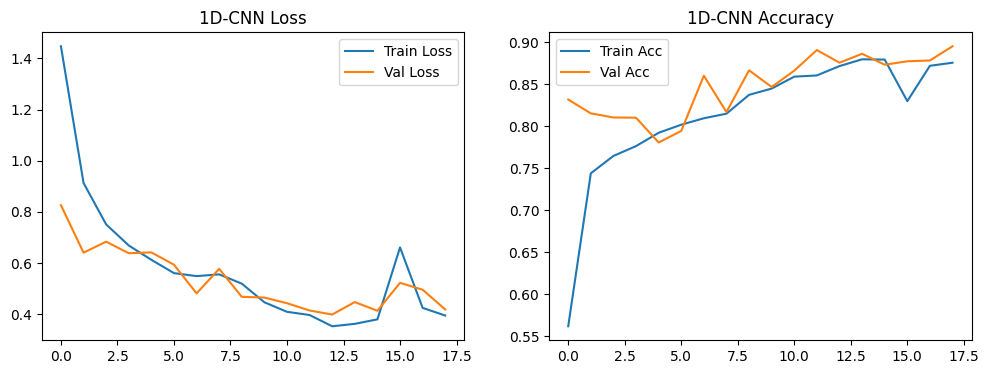

In [9]:
# Remodelage des données pour le 1D-CNN
X_train_cnn = X_train_proc.reshape((X_train_proc.shape[0], X_train_proc.shape[1], 1))
X_val_cnn = X_val_proc.reshape((X_val_proc.shape[0], X_val_proc.shape[1], 1))
X_test_cnn = X_test_proc.reshape((X_test_proc.shape[0], X_test_proc.shape[1], 1))

print("Nouvelles dimensions pour 1D-CNN :", X_train_cnn.shape)

def build_cnn1d(input_shape):
    model = Sequential([
        Input(shape=input_shape),
        Conv1D(64, kernel_size=3, activation='relu', padding='same'),
        MaxPooling1D(pool_size=2),
        Conv1D(128, kernel_size=3, activation='relu', padding='same'),
        GlobalMaxPooling1D(),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(5, activation='softmax')
    ])
    model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

cnn_model = build_cnn1d((X_train_proc.shape[1], 1))
cnn_model.summary()

callbacks_cnn = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ModelCheckpoint('./nids_artifacts/cnn1d_checkpoint.keras', save_best_only=True, monitor='val_loss')
]

print("Entraînement du 1D-CNN...")
history_cnn = cnn_model.fit(
    X_train_cnn, y_train_enc,
    validation_data=(X_val_cnn, y_val_enc),
    epochs=30,
    batch_size=128,
    class_weight=class_weight_dict,
    callbacks=callbacks_cnn,
    verbose=1
)

# Tracer les courbes d'apprentissage pour le 1D-CNN
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_cnn.history['loss'], label='Train Loss')
plt.plot(history_cnn.history['val_loss'], label='Val Loss')
plt.title('1D-CNN Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_cnn.history['accuracy'], label='Train Acc')
plt.plot(history_cnn.history['val_accuracy'], label='Val Acc')
plt.title('1D-CNN Accuracy')
plt.legend()
plt.show()

```markdown
## Étape 6 : Évaluation Comparative sur Validation, Explicabilité & Évaluation Finale sur Test

Nous allons évaluer de manière exhaustive nos trois modèles sur le jeu de validation pour sélectionner les meilleurs hyperparamètres, expliquer globalement les features clés à l'aide de **SHAP**, puis valider définitivement nos modèles sur le jeu de test indépendant.
```

224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
224/224 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step

=== Tableau Comparatif de Validation ===
               Accuracy  Macro F1 Weighted F1 Recall R2L Recall U2R       FPR Latency (ms)
Random Forest  0.989944  0.933994    0.989897   0.976293   0.583333  0.002945     0.018589
MLP             0.94148  0.765896     0.95206   0.924569   0.916667  0.012959     0.162114
1D-CNN         0.875838  0.692511    0.895142   0.900862   0.916667  0.028048     0.720686


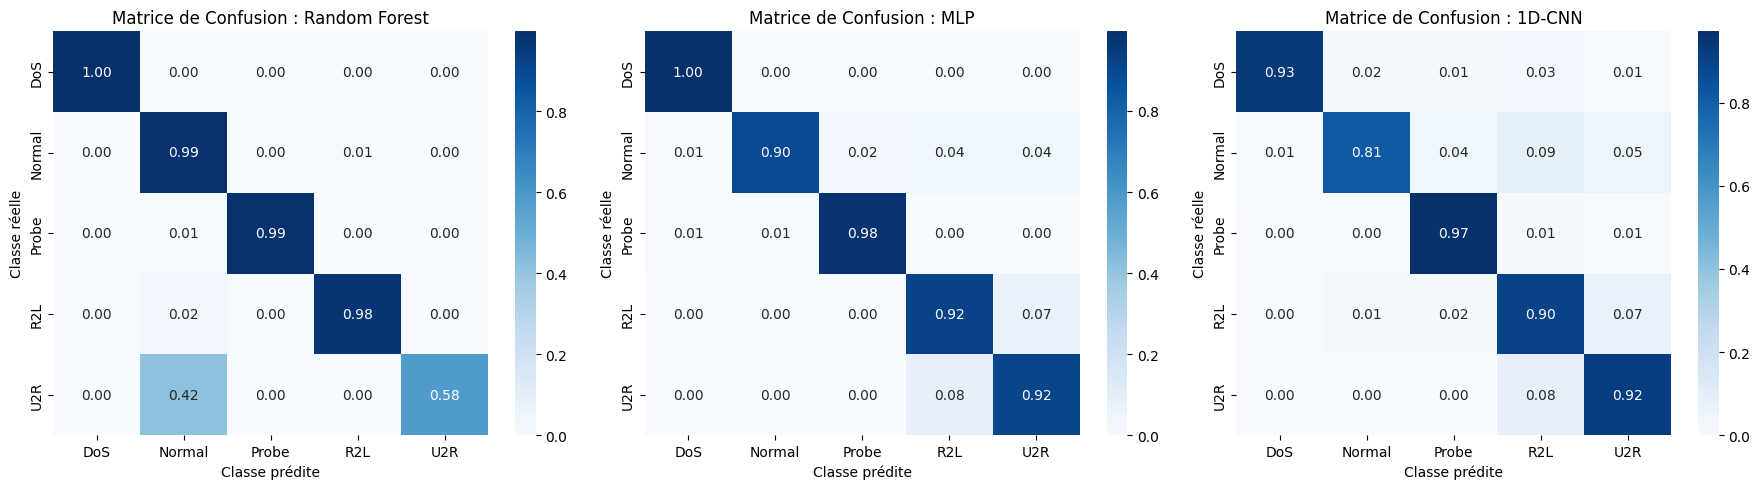

In [10]:
def calculate_fpr(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    # Pour un système multiclasse, nous calculons le taux de faux positifs moyen
    fpr_list = []
    for i in range(len(cm)):
        fp = cm[:, i].sum() - cm[i, i]
        tn = cm.sum() - (cm[i, :].sum() + cm[:, i].sum() - cm[i, i])
        fpr_list.append(fp / (fp + tn) if (fp + tn) > 0 else 0)
    return np.mean(fpr_list)

def evaluate_model_full(model, X_data, y_true, is_cnn=False):
    t0 = time.time()
    if is_cnn:
        probs = model.predict(X_data)
        preds = np.argmax(probs, axis=1)
    elif hasattr(model, "predict_proba"):
        preds = model.predict(X_data)
    else:
        probs = model.predict(X_data)
        preds = np.argmax(probs, axis=1)

    latency_ms = ((time.time() - t0) / len(X_data)) * 1000

    acc = accuracy_score(y_true, preds)
    macro_f1 = f1_score(y_true, preds, average='macro')
    weighted_f1 = f1_score(y_true, preds, average='weighted')

    # Classes R2L et U2R
    rep = classification_report(y_true, preds, output_dict=True, zero_division=0)
    # Récupération des rappels (recalls) par classe via indexation
    r2l_idx = str(label_encoder.transform(['R2L'])[0])
    u2r_idx = str(label_encoder.transform(['U2R'])[0])

    r2l_recall = rep.get(r2l_idx, {}).get('recall', 0.0)
    u2r_recall = rep.get(u2r_idx, {}).get('recall', 0.0)
    fpr = calculate_fpr(y_true, preds)

    return {
        'Accuracy': acc,
        'Macro F1': macro_f1,
        'Weighted F1': weighted_f1,
        'Recall R2L': r2l_recall,
        'Recall U2R': u2r_recall,
        'FPR': fpr,
        'Latency (ms)': latency_ms,
        'Predictions': preds
    }

# Évaluation comparative sur validation
metrics_rf = evaluate_model_full(best_rf_model, X_val_proc, y_val_enc, is_cnn=False)
metrics_mlp = evaluate_model_full(mlp_model, X_val_proc, y_val_enc, is_cnn=False)
metrics_cnn = evaluate_model_full(cnn_model, X_val_cnn, y_val_enc, is_cnn=True)

df_compare = pd.DataFrame({
    'Random Forest': metrics_rf,
    'MLP': metrics_mlp,
    '1D-CNN': metrics_cnn
}).T.drop(columns=['Predictions'])

print("\n=== Tableau Comparatif de Validation ===")
print(df_compare.to_string())

# Matrices de confusion comparatives
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models_preds = [metrics_rf['Predictions'], metrics_mlp['Predictions'], metrics_cnn['Predictions']]
names = ['Random Forest', 'MLP', '1D-CNN']

for i, (preds, name) in enumerate(zip(models_preds, names)):
    cm = confusion_matrix(y_val_enc, preds, normalize='true')
    sns.heatmap(
        cm, annot=True, fmt='.2f', cmap='Blues', ax=axes[i],
        xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_
    )
    axes[i].set_title(f"Matrice de Confusion : {name}")
    axes[i].set_xlabel("Classe prédite")
    axes[i].set_ylabel("Classe réelle")

plt.tight_layout()
plt.show()

Explication globale du modèle Random Forest à l'aide de SHAP...


/tmp/ipykernel_874/3631592925.py:24: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


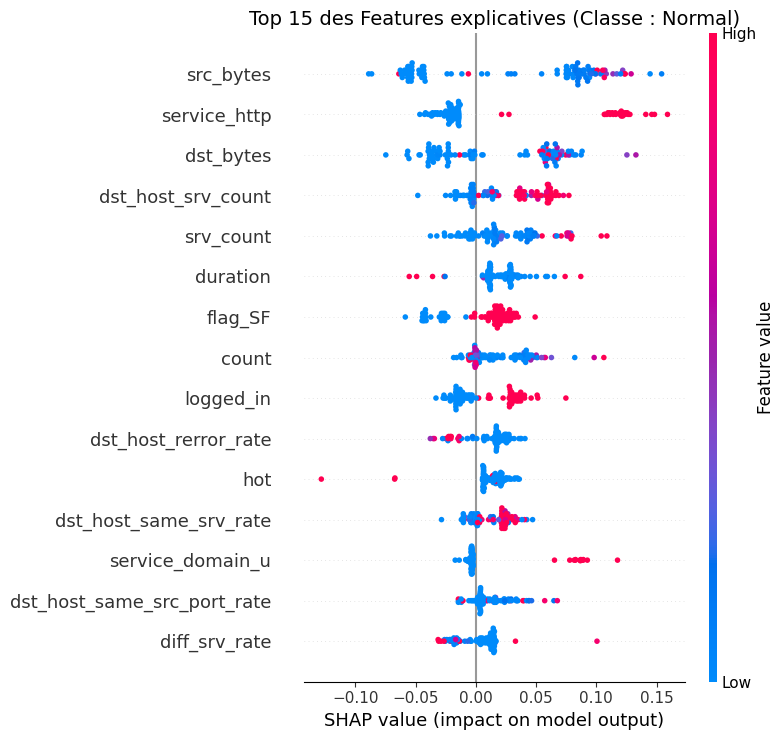

In [16]:
# === Explicabilité (XAI) globale avec SHAP sur Random Forest ===
print("Explication globale du modèle Random Forest à l'aide de SHAP...")
# Extraction d'un échantillon représentatif de validation pour accélérer le calcul
shap_sample_idx = np.random.choice(X_val_proc.shape[0], size=100, replace=False)
X_shap_sample = X_val_proc[shap_sample_idx]

explainer = shap.TreeExplainer(best_rf_model)
shap_values = explainer.shap_values(X_shap_sample)

# Dans SHAP pour les modèles multiclasses, shap_values est soit une liste de matrices,
# soit un tableau numpy à 3 dimensions de forme (échantillons, features, classes).
# Nous convertissons de manière robuste en inspectant la structure.
if isinstance(shap_values, list):
    # On prend la matrice correspondant à la classe d'index 1 (Normal)
    shap_to_plot = shap_values[1]
elif isinstance(shap_values, np.ndarray) and len(shap_values.shape) == 3:
    # Si c'est un tableau (échantillons, features, classes), on extrait l'index de la classe 'Normal' (1)
    shap_to_plot = shap_values[:, :, 1]
else:
    shap_to_plot = shap_values

# Résumé global de l'importance des variables sous forme graphique
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_to_plot,
    X_shap_sample,
    feature_names=all_features,
    max_display=15,
    show=False
)
plt.title("Top 15 des Features explicatives (Classe : Normal)", fontsize=14)
plt.tight_layout()
plt.show()

In [12]:
# === Évaluation finale UNIQUE sur le Test Set indépendant ===
print("\n================ EVALUATION FINALE SUR LE TEST SET NEUTRE ================")
final_rf = evaluate_model_full(best_rf_model, X_test_proc, y_test_enc, is_cnn=False)
final_mlp = evaluate_model_full(mlp_model, X_test_proc, y_test_enc, is_cnn=False)
final_cnn = evaluate_model_full(cnn_model, X_test_cnn, y_test_enc, is_cnn=True)

df_test_compare = pd.DataFrame({
    'Random Forest (Test)': final_rf,
    'MLP (Test)': final_mlp,
    '1D-CNN (Test)': final_cnn
}).T.drop(columns=['Predictions'])

print(df_test_compare.to_string())

# Afficher le rapport de classification complet du meilleur classifieur global sur le Test Set
print("\n--- Classification Report - Random Forest (Test Set) ---")
print(classification_report(y_test_enc, final_rf['Predictions'], target_names=label_encoder.classes_))


================ EVALUATION FINALE SUR LE TEST SET NEUTRE ================
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
224/224 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
                      Accuracy  Macro F1 Weighted F1 Recall R2L Recall U2R       FPR Latency (ms)
Random Forest (Test)   0.98827  0.935584    0.988281   0.956897   0.666667   0.00342      0.03088
MLP (Test)            0.943583  0.765706    0.953414   0.883621   0.916667  0.012692     0.147619
1D-CNN (Test)         0.873761  0.686542    0.894279   0.877155       0.75  0.028541     0.241519

--- Classification Report - Random Forest (Test Set) ---
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00      2504
      Normal       0.99      0.99      0.99      3474
       Probe       0.99      0.99      0.99       707
         R2L       0.92      0.96      0.94       464
         U2R       0.89      0.67      0.76        12

    accuracy                           0.99      7161
   macro avg

```markdown
## Étape 7 : Export des Modèles & Pipeline d'Inférence Personnel

Nous allons exporter tous nos artefacts d'entraînement pour permettre une utilisation immédiate et locale du NIDS sans aucune fuite.
```

In [17]:
import os
import zipfile
import json
import joblib

print("=== 1. LISTE DES FICHIERS DANS LE DOSSIER D'EXPORT ===")
artifacts_dir = './nids_artifacts/'
if os.path.exists(artifacts_dir):
    files = os.listdir(artifacts_dir)
    for f in files:
        size_kb = os.path.getsize(os.path.join(artifacts_dir, f)) / 1024
        print(f" - {f:<30} ({size_kb:.2f} KB)")
else:
    print("Le dossier './nids_artifacts/' n'existe pas !")

print("\n=== 2. VÉRIFICATION DU CONTENU DE L'ARCHIVE ZIP ===")
zip_path = './nids_models_ready.zip'
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_files = zip_ref.namelist()
        print(f"L'archive '{zip_path}' contient {len(zip_files)} fichiers :")
        for f in zip_files:
            print(f" - {f}")
else:
    print("L'archive zip 'nids_models_ready.zip' est introuvable !")

print("\n=== 3. INSPECTION DE LA CONFIGURATION DES METADONNÉES (feature_columns.json) ===")
config_path = os.path.join(artifacts_dir, 'feature_columns.json')
if os.path.exists(config_path):
    with open(config_path, 'r') as f:
        meta_config = json.load(f)
        print("Colonnes catégorielles configurées :", meta_config.get('categorical'))
        print("Nombre de colonnes numériques :", len(meta_config.get('numerical', [])))
        print("Nombre total de features brutes attendues :", len(meta_config.get('columns', [])))
else:
    print("Fichier 'feature_columns.json' manquant !")

print("\n=== 4. INSPECTION DE L'ENCODEUR ET DU MAPPING DES CLASSES (label_encoder.joblib) ===")
le_path = os.path.join(artifacts_dir, 'label_encoder.joblib')
if os.path.exists(le_path):
    le = joblib.load(le_path)
    classes_mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    print("Mapping officiel des 5 classes récupéré du LabelEncoder :")
    for k, v in classes_mapping.items():
        print(f"  - {k} -> {v}")
else:
    print("Fichier 'label_encoder.joblib' manquant !")

print("\n=== 5. CHARGEMENT ET SÉCURITÉ DU PREPROCESSOR / COLUMNTRANSFORMER ===")
prep_path = os.path.join(artifacts_dir, 'preprocessor.joblib')
if os.path.exists(prep_path):
    prep = joblib.load(prep_path)
    print("Type du préprocesseur chargé :", type(prep))
    # Vérification que StandardScaler et OneHotEncoder sont présents à l'intérieur du ColumnTransformer
    for name, transformer, cols in prep.transformers_:
        print(f"  - Étape : '{name}' utilisant {type(transformer).__name__} sur {len(cols)} colonnes.")
else:
    print("Fichier 'preprocessor.joblib' manquant !")

=== 1. LISTE DES FICHIERS DANS LE DOSSIER D'EXPORT ===
 - cnn1d_model.keras              (429.54 KB)
 - rf_model.joblib                (31230.03 KB)
 - preprocessor.joblib            (6.38 KB)
 - cnn1d_checkpoint.keras         (429.54 KB)
 - metrics_summary.json           (1.12 KB)
 - feature_columns.json           (2.14 KB)
 - label_encoder.joblib           (0.50 KB)
 - mlp_model.keras                (308.23 KB)
 - mlp_checkpoint.keras           (308.23 KB)

=== 2. VÉRIFICATION DU CONTENU DE L'ARCHIVE ZIP ===
L'archive './nids_models_ready.zip' contient 9 fichiers :
 - cnn1d_model.keras
 - rf_model.joblib
 - preprocessor.joblib
 - cnn1d_checkpoint.keras
 - metrics_summary.json
 - feature_columns.json
 - label_encoder.joblib
 - mlp_model.keras
 - mlp_checkpoint.keras

=== 3. INSPECTION DE LA CONFIGURATION DES METADONNÉES (feature_columns.json) ===
Colonnes catégorielles configurées : ['protocol_type', 'service', 'flag']
Nombre de colonnes numériques : 38
Nombre total de features brutes

In [13]:
# Sauvegarde des modèles
joblib.dump(best_rf_model, './nids_artifacts/rf_model.joblib')
mlp_model.save('./nids_artifacts/mlp_model.keras')
cnn_model.save('./nids_artifacts/cnn1d_model.keras')

# Sauvegarde des préprocesseurs et encodeurs
joblib.dump(preprocessor, './nids_artifacts/preprocessor.joblib')
joblib.dump(label_encoder, './nids_artifacts/label_encoder.joblib')

# Sauvegarde de la configuration des colonnes d'origine et des métriques
with open('./nids_artifacts/feature_columns.json', 'w') as f:
    json.dump({
        'columns': list(X_train.columns),
        'categorical': categorical_cols,
        'numerical': numerical_cols
    }, f, indent=4)

# Résumé des métriques de validation finales
metrics_summary = df_test_compare.to_dict()
with open('./nids_artifacts/metrics_summary.json', 'w') as f:
    json.dump(metrics_summary, f, default=str, indent=4)

print("Tous les artefacts de pré-traitement, modèles et configurations ont été enregistrés avec succès.")

Tous les artefacts de pré-traitement, modèles et configurations ont été enregistrés avec succès.


In [14]:
# === Définition de la fonction autonome d'inférence ===
def predict_network_flow(df_raw, model_choice='rf'):
    """
    Fonction d'inférence autonome prenant un flux brut réseau (DataFrame Pandas)
    et retournant la classe d'attaque détectée et la distribution de probabilité associée.
    """
    # Chargement dynamique des préprocesseurs
    prep = joblib.load('./nids_artifacts/preprocessor.joblib')
    le = joblib.load('./nids_artifacts/label_encoder.joblib')

    with open('./nids_artifacts/feature_columns.json', 'r') as f:
        meta = json.load(f)

    # Alignement strict des colonnes pour s'assurer de l'absence de colonnes manquantes
    df_aligned = df_raw.copy()
    for col in meta['columns']:
        if col not in df_aligned.columns:
            df_aligned[col] = 0.0

    df_aligned = df_aligned[meta['columns']]

    # Application du préprocesseur
    X_proc = prep.transform(df_aligned)

    # Sélection du modèle et prédiction
    if model_choice == 'rf':
        model = joblib.load('./nids_artifacts/rf_model.joblib')
        probs = model.predict_proba(X_proc)
        preds = np.argmax(probs, axis=1)
    elif model_choice == 'mlp':
        model = load_model('./nids_artifacts/mlp_model.keras')
        probs = model.predict(X_proc, verbose=0)
        preds = np.argmax(probs, axis=1)
    elif model_choice == 'cnn':
        model = load_model('./nids_artifacts/cnn1d_model.keras')
        X_cnn = X_proc.reshape((X_proc.shape[0], X_proc.shape[1], 1))
        probs = model.predict(X_cnn, verbose=0)
        preds = np.argmax(probs, axis=1)
    else:
        raise ValueError("Choix du modèle invalide. Utilisez 'rf', 'mlp' ou 'cnn'.")

    # Retourner les labels textuels et les probabilités détaillées
    labels = le.inverse_transform(preds)
    return labels, probs

# --- Test Unitaire Autonome de la fonction d'inférence ---
sample_flow = X_test.iloc[[0]]
pred_label, pred_prob = predict_network_flow(sample_flow, model_choice='rf')

print("\n--- Test d'Inférence Autonome Réussi ---")
print(f"Flux analysé (Classe attendue : {y_test.iloc[0]}) -> Classe prédite : {pred_label[0]} (Confiance : {np.max(pred_prob[0])*100:.2f}%)")


--- Test d'Inférence Autonome Réussi ---
Flux analysé (Classe attendue : Normal) -> Classe prédite : Normal (Confiance : 100.00%)


In [15]:
# === Création de l'archive ZIP prête pour le téléchargement ===
import shutil
shutil.make_archive('nids_models_ready', 'zip', './nids_artifacts/')
print("Archive zip 'nids_models_ready.zip' créée avec succès et disponible pour le téléchargement.")

Archive zip 'nids_models_ready.zip' créée avec succès et disponible pour le téléchargement.
